<a href="https://colab.research.google.com/github/kimheeseo/LSCNS/blob/main/SEM_CNN_gradcam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 광섬유 SEM CNN — 단계별 실행

위에서 아래 순서로 실행하세요. Colab에서 T4 GPU를 권장합니다. 중간 단계부터 재실행하려면 그 이전 단계가 완료되어 있어야 합니다. 마지막 단계 완료 후에는 임시 데이터가 삭제됩니다.

## 1. Google Drive 연결 및 라이브러리

Google Drive를 연결하고 학습에 필요한 라이브러리를 불러옵니다.

In [1]:
# -*- coding: utf-8 -*-
r"""SEM 분류기. Colab: !python SEM_CNN_3epoch.py
Windows: python SEM_CNN_3epoch.py --data-dir "D:\path\Fiber_Category_Renamed_PNG"
필요 패키지: torch torchvision numpy pandas pillow scikit-learn tqdm
전체 %는 단계별 가중치에 기반한 진행률이며 예상 소요시간 비율이 아닙니다.
"""
import sys, argparse, tempfile
from pathlib import Path
parser=argparse.ArgumentParser(description='SEM CNN: 3 epoch')
parser.add_argument('--data-dir', help='Fiber_Category_Renamed_PNG 폴더 경로')
parser.add_argument('--output-dir', help='결과를 저장할 상위 폴더')
args=parser.parse_known_args()[0]
try:
    import google.colab
    IN_COLAB=True
except ImportError:
    IN_COLAB=False
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
from pathlib import Path
import os, random, hashlib, shutil, json, time
import numpy as np, pandas as pd
import torch
from PIL import Image, ImageOps
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from torchvision import transforms, models
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm


Mounted at /content/drive


## 2. 학습 설정

기본값은 3 epoch, 원본 1장당 증강 이미지 3장입니다.

In [2]:
SEED=42; EPOCHS=10; BATCH_SIZE=32; IMG_SIZE=224
AUG_PER_IMAGE=3  # 원본 1장 + 증강 3장; 속도에 따라 조절
CLASSES=['bending','cleaving','fracture']
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('장치:',device)
if device.type=='cpu': print('GPU가 없어 시간이 오래 걸릴 수 있습니다. 런타임 설정에서 T4 GPU를 선택하세요.')


장치: cuda


## 3. 진행률과 저장 경로 설정

원본 폴더와 결과 폴더를 지정합니다. 전체 진행률은 단계별 가중치이며 시간 비율은 아닙니다.

In [3]:
# 전체 진행률은 단계별 가중치를 사용한 작업량 지표이며 시간 예측이 아닙니다.
def progress(items, start, end, title, total=None):
    total = len(items) if total is None else int(total)
    print(f"[전체 {start:.1f}%] {title} 시작 (총 {total})", flush=True)
    next_mark=0
    for i, item in enumerate(items,1):
        yield item
        pct=start+(end-start)*i/max(total,1)
        phase=100*i/max(total,1)
        if phase >= next_mark or i==total:
            print(f"[전체 {pct:.1f}%] {title}: {i}/{total} ({phase:.0f}%)",flush=True)
            next_mark=(int(phase)//10+1)*10
    if not total: print(f"[전체 {end:.1f}%] {title}: 처리할 항목 없음",flush=True)
if args.data_dir:
    DATA_DIR=Path(args.data_dir).expanduser()
elif IN_COLAB:
    DATA_DIR=Path('/content/drive/MyDrive/Fiber_Category_Renamed_PNG')
else:
    raise SystemExit('PC에서는 --data-dir 로 데이터 폴더 경로를 지정하세요.')
assert DATA_DIR.is_dir(), f'폴더 없음: {DATA_DIR}'
out=Path(args.output_dir).expanduser() if args.output_dir else (Path('/content/drive/MyDrive/SEM_CNN_3epoch') if IN_COLAB else DATA_DIR.parent/'SEM_CNN_3epoch')
RUN=out/time.strftime('%Y%m%d_%H%M%S')
RUN.mkdir(parents=True,exist_ok=False)
LOCAL=Path(tempfile.mkdtemp(prefix='sem_cnn_'))
print('원본 폴더:',DATA_DIR,'결과 저장:',RUN,flush=True)


원본 폴더: /content/drive/MyDrive/Fiber_Category_Renamed_PNG 결과 저장: /content/drive/MyDrive/SEM_CNN_3epoch/20261108_041728


## 4. 원본 이미지 확인

폴더 라벨과 HCF 여부를 확인합니다. 중복 이미지도 모두 포함하며 열 수 없는 파일은 건너뜁니다.

In [4]:
# 이미지 읽기 확인 및 폴더별 라벨 부여: 동일 사진도 모두 포함
rows = []
files = []
for label in CLASSES:
    root = DATA_DIR / label
    assert root.is_dir(), f'폴더 없음: {root}'
    files.extend((label, p) for p in sorted(root.rglob('*'))
                 if p.suffix.lower() in {'.png', '.jpg', '.jpeg', '.tif', '.tiff'})

for label, p in progress(files, 0, 15, '원본 확인'):
    root = DATA_DIR / label
    try:
        with Image.open(p) as im:
            ImageOps.exif_transpose(im).convert('RGB').load()
    except Exception as e:
        print('읽기 실패:', p, e)
        continue
    rows.append({
        'path': str(p),
        'label': label,
        'hcf': any(x.lower() == 'hcf' for x in p.relative_to(root).parts[:-1])
               or 'hcf' in p.stem.lower(),
    })

df = pd.DataFrame(rows)
assert len(df) > 0, '이미지가 없습니다.'
print(pd.crosstab(df.label, df.hcf))
print('사용할 이미지 전체:', len(df))


[전체 0.0%] 원본 확인 시작 (총 678)
[전체 0.0%] 원본 확인: 1/678 (0%)
[전체 1.5%] 원본 확인: 68/678 (10%)
[전체 3.0%] 원본 확인: 136/678 (20%)
[전체 4.5%] 원본 확인: 204/678 (30%)
[전체 6.0%] 원본 확인: 272/678 (40%)
[전체 7.5%] 원본 확인: 339/678 (50%)
[전체 9.0%] 원본 확인: 407/678 (60%)
[전체 10.5%] 원본 확인: 475/678 (70%)
[전체 12.0%] 원본 확인: 543/678 (80%)
[전체 13.5%] 원본 확인: 611/678 (90%)
[전체 15.0%] 원본 확인: 678/678 (100%)
hcf       False  True 
label                 
bending     146      0
cleaving    301    105
fracture    118      8
사용할 이미지 전체: 678


## 5. 학습·검증·테스트 분할

증강 전에 원본을 70:15:15로 분할하고 manifest.csv를 저장합니다. 동일 시편의 다른 사진은 자동으로 묶이지 않으니 결과를 확인하세요.

같은 사진이 여러 폴더나 파일로 존재하면 서로 다른 분할에 들어갈 수 있어 평가 정확도가 높게 나올 수 있습니다.

In [5]:
# 유형을 기준으로 70/15/15 분할. HCF 표본이 작으면 각 분할에 없을 수 있음.
idx=np.arange(len(df)); y=df.label
train,tmp=train_test_split(idx,test_size=.30,random_state=SEED,stratify=y)
val,test=train_test_split(tmp,test_size=.5,random_state=SEED,stratify=y.iloc[tmp])
df['split']=''; df.loc[train,'split']='train'; df.loc[val,'split']='val'; df.loc[test,'split']='test'
df.to_csv(RUN/'manifest.csv',index=False,encoding='utf-8-sig')
print(pd.crosstab([df['split'],df.label],df.hcf))


hcf             False  True 
split label                 
test  bending      22      0
      cleaving     50     11
      fracture     19      0
train bending     102      0
      cleaving    203     81
      fracture     80      8
val   bending      22      0
      cleaving     48     13
      fracture     19      0


## 6. 학습 이미지 증강 및 저장

학습용 이미지만 증강해 Google Drive에 저장합니다.

In [6]:
# train 원본만 증강하여 Drive에 저장한 다음, 저장된 파일을 로컬에 복사해 학습합니다.
aug=transforms.Compose([transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(), transforms.RandomRotation(20), transforms.ColorJitter(brightness=.12,contrast=.12)])
resize=transforms.Resize((IMG_SIZE,IMG_SIZE))
saved=RUN/'augmented_train'
for i,row in progress(df[df.split=='train'].iterrows(),15,45,'증강 및 저장',total=(df.split=='train').sum()):
    with Image.open(row.path) as im: im=resize(ImageOps.exif_transpose(im).convert('RGB'))
    folder=saved/row.label/('HCF' if row.hcf else 'standard'); folder.mkdir(parents=True,exist_ok=True)
    im.save(folder/f'{i:05d}_original.png')
    for k in range(AUG_PER_IMAGE): aug(im).save(folder/f'{i:05d}_aug{k+1}.png')


[전체 15.0%] 증강 및 저장 시작 (총 474)
[전체 15.1%] 증강 및 저장: 1/474 (0%)
[전체 18.0%] 증강 및 저장: 48/474 (10%)
[전체 21.0%] 증강 및 저장: 95/474 (20%)
[전체 24.1%] 증강 및 저장: 143/474 (30%)
[전체 27.0%] 증강 및 저장: 190/474 (40%)
[전체 30.0%] 증강 및 저장: 237/474 (50%)
[전체 33.0%] 증강 및 저장: 285/474 (60%)
[전체 36.0%] 증강 및 저장: 332/474 (70%)
[전체 39.1%] 증강 및 저장: 380/474 (80%)
[전체 42.0%] 증강 및 저장: 427/474 (90%)
[전체 45.0%] 증강 및 저장: 474/474 (100%)


## 7. 저장된 증강 이미지 다시 불러오기

저장된 이미지를 로컬 임시 폴더로 읽어 학습 속도를 높입니다.

In [7]:
# Drive에서 다시 읽어 로컬로 복사: epoch마다 Drive I/O 반복 방지
aug_files=list(saved.rglob('*.png'))
for src in progress(aug_files,45,55,'저장된 증강 이미지 다시 불러오기'):
    dst=LOCAL/'train'/src.relative_to(saved); dst.parent.mkdir(parents=True,exist_ok=True); shutil.copy2(src,dst)
for split in ['val','test']:
    for i,row in progress(df[df.split==split].iterrows(),55 if split=='val' else 57.5,57.5 if split=='val' else 60,split+' 로컬 복사',total=(df.split==split).sum()):
        dst=LOCAL/split/row.label/('HCF' if row.hcf else 'standard'); dst.mkdir(parents=True,exist_ok=True)
        with Image.open(row.path) as im: resize(ImageOps.exif_transpose(im).convert('RGB')).save(dst/f'{i:05d}.png')
print('증강본 저장:',saved)


[전체 45.0%] 저장된 증강 이미지 다시 불러오기 시작 (총 1896)
[전체 45.0%] 저장된 증강 이미지 다시 불러오기: 1/1896 (0%)
[전체 46.0%] 저장된 증강 이미지 다시 불러오기: 190/1896 (10%)
[전체 47.0%] 저장된 증강 이미지 다시 불러오기: 380/1896 (20%)
[전체 48.0%] 저장된 증강 이미지 다시 불러오기: 569/1896 (30%)
[전체 49.0%] 저장된 증강 이미지 다시 불러오기: 759/1896 (40%)
[전체 50.0%] 저장된 증강 이미지 다시 불러오기: 948/1896 (50%)
[전체 51.0%] 저장된 증강 이미지 다시 불러오기: 1138/1896 (60%)
[전체 52.0%] 저장된 증강 이미지 다시 불러오기: 1328/1896 (70%)
[전체 53.0%] 저장된 증강 이미지 다시 불러오기: 1517/1896 (80%)
[전체 54.0%] 저장된 증강 이미지 다시 불러오기: 1707/1896 (90%)
[전체 55.0%] 저장된 증강 이미지 다시 불러오기: 1896/1896 (100%)
[전체 55.0%] val 로컬 복사 시작 (총 102)
[전체 55.0%] val 로컬 복사: 1/102 (1%)
[전체 55.3%] val 로컬 복사: 11/102 (11%)
[전체 55.5%] val 로컬 복사: 21/102 (21%)
[전체 55.8%] val 로컬 복사: 31/102 (30%)
[전체 56.0%] val 로컬 복사: 41/102 (40%)
[전체 56.2%] val 로컬 복사: 51/102 (50%)
[전체 56.5%] val 로컬 복사: 62/102 (61%)
[전체 56.8%] val 로컬 복사: 72/102 (71%)
[전체 57.0%] val 로컬 복사: 82/102 (80%)
[전체 57.3%] val 로컬 복사: 92/102 (90%)
[전체 57.5%] val 로컬 복사: 102/102 (100%)
[전체 57.5%] test 로컬 복사 시작 (총 102)

## 8. 데이터 로더 준비

이미지와 정답을 모델에 전달할 데이터 로더를 준비합니다.

In [8]:
norm=transforms.Compose([transforms.ToTensor(),transforms.Normalize([.485,.456,.406],[.229,.224,.225])])
class SemData(Dataset):
    def __init__(self,split):
        self.items=[(p,CLASSES.index(p.parent.parent.name),p.parent.name=='HCF') for p in sorted((LOCAL/split).rglob('*.png'))]
    def __len__(self): return len(self.items)
    def __getitem__(self,i):
        p,y,h=self.items[i]
        with Image.open(p) as im: x=norm(im.convert('RGB'))
        return x,y,h
sets={s:SemData(s) for s in ['train','val','test']}
loaders={s:DataLoader(d,batch_size=BATCH_SIZE,shuffle=(s=='train'),num_workers=0,pin_memory=device.type=='cuda') for s,d in sets.items()}
print({s:len(d) for s,d in sets.items()})


{'train': 1896, 'val': 102, 'test': 102}


## 9. 모델 및 최적화 설정

사전학습 ResNet18의 분류기를 구성합니다.

In [9]:
# 사전학습 모델의 분류기만 학습: 빠르고 작은 데이터에서 과적합을 줄이는 출발점
model=models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for p in model.parameters(): p.requires_grad=False
model.fc=torch.nn.Sequential(torch.nn.Dropout(.3),torch.nn.Linear(model.fc.in_features,3))
model.to(device)
counts=np.bincount([y for _,y,_ in sets['train'].items],minlength=3)
weights=torch.tensor(len(sets['train'])/(3*counts),dtype=torch.float32,device=device)
loss_fn=torch.nn.CrossEntropyLoss(weight=weights); optimizer=torch.optim.AdamW(model.fc.parameters(),lr=.001,weight_decay=.01)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 134MB/s]


## 10. 3 epoch 학습

학습과 검증을 진행하고 검증 손실이 가장 낮은 모델을 저장합니다.

In [10]:
best=float('inf'); history=[]
for epoch in range(EPOCHS):
    model.eval(); model.fc.train()  # 동결 backbone의 BatchNorm 통계 유지
    total=correct=loss_sum=0
    for x,y,_ in progress(loaders['train'],60+epoch*10,68+epoch*10,f'Epoch {epoch+1}/{EPOCHS} 학습'):
        x,y=x.to(device),y.to(device); optimizer.zero_grad(set_to_none=True)
        z=model(x); loss=loss_fn(z,y); loss.backward(); optimizer.step()
        total+=y.size(0); correct+=(z.argmax(1)==y).sum().item(); loss_sum+=loss.item()*y.size(0)
    model.eval(); vl=vc=vn=0
    with torch.no_grad():
        for x,y,_ in progress(loaders['val'],68+epoch*10,70+epoch*10,f'Epoch {epoch+1}/{EPOCHS} 검증'):
            x,y=x.to(device),y.to(device); z=model(x); vl+=loss_fn(z,y).item()*len(y); vc+=(z.argmax(1)==y).sum().item(); vn+=len(y)
    row={'epoch':epoch+1,'train_loss':loss_sum/total,'train_acc':correct/total,'val_loss':vl/vn,'val_acc':vc/vn}; history.append(row); print(row)
    if vl/vn<best:
        best=vl/vn; torch.save({'state_dict':model.state_dict(),'classes':CLASSES,'image_size':IMG_SIZE,'epoch':epoch+1},RUN/'best_model.pt')
pd.DataFrame(history).to_csv(RUN/'history.csv',index=False)


[전체 60.0%] Epoch 1/10 학습 시작 (총 60)
[전체 60.1%] Epoch 1/10 학습: 1/60 (2%)
[전체 60.8%] Epoch 1/10 학습: 6/60 (10%)
[전체 61.6%] Epoch 1/10 학습: 12/60 (20%)
[전체 62.4%] Epoch 1/10 학습: 18/60 (30%)
[전체 63.2%] Epoch 1/10 학습: 24/60 (40%)
[전체 64.0%] Epoch 1/10 학습: 30/60 (50%)
[전체 64.8%] Epoch 1/10 학습: 36/60 (60%)
[전체 65.6%] Epoch 1/10 학습: 42/60 (70%)
[전체 66.4%] Epoch 1/10 학습: 48/60 (80%)
[전체 67.2%] Epoch 1/10 학습: 54/60 (90%)
[전체 68.0%] Epoch 1/10 학습: 60/60 (100%)
[전체 68.0%] Epoch 1/10 검증 시작 (총 4)
[전체 68.5%] Epoch 1/10 검증: 1/4 (25%)
[전체 69.0%] Epoch 1/10 검증: 2/4 (50%)
[전체 69.5%] Epoch 1/10 검증: 3/4 (75%)
[전체 70.0%] Epoch 1/10 검증: 4/4 (100%)
{'epoch': 1, 'train_loss': 1.0278531229948695, 'train_acc': 0.510548523206751, 'val_loss': 0.7899213947501837, 'val_acc': 0.6568627450980392}
[전체 70.0%] Epoch 2/10 학습 시작 (총 60)
[전체 70.1%] Epoch 2/10 학습: 1/60 (2%)
[전체 70.8%] Epoch 2/10 학습: 6/60 (10%)
[전체 71.6%] Epoch 2/10 학습: 12/60 (20%)
[전체 72.4%] Epoch 2/10 학습: 18/60 (30%)
[전체 73.2%] Epoch 2/10 학습: 24/60 (40%)
[전체 74

## 11. 테스트 및 결과 저장

최적 모델을 테스트하고 혼동행렬과 예측 결과를 저장합니다.

In [11]:
# 최적 검증 손실 모델을 고정된 test에서 1회 평가
checkpoint=torch.load(RUN/'best_model.pt',map_location=device,weights_only=True); model.load_state_dict(checkpoint['state_dict']); model.eval()
truth=[]; pred=[]; hcf=[]
with torch.no_grad():
    for x,y,h in progress(loaders['test'],90,99,'테스트 평가'):
        truth.extend(y.tolist()); pred.extend(model(x.to(device)).argmax(1).cpu().tolist()); hcf.extend(h.tolist())
report=classification_report(truth,pred,labels=list(range(3)),target_names=CLASSES,zero_division=0)
print('선택 epoch:',checkpoint['epoch']); print(report)
cm=confusion_matrix(truth,pred,labels=list(range(3)))
print('행=실제, 열=예측\n',cm)
pd.DataFrame(cm,index=CLASSES,columns=CLASSES).to_csv(RUN/'test_confusion_matrix.csv')
results=pd.DataFrame({'path':[str(p) for p,_,_ in sets['test'].items], 'true':[CLASSES[i] for i in truth],'pred':[CLASSES[i] for i in pred],'hcf':hcf})
results.to_csv(RUN/'test_predictions.csv',index=False,encoding='utf-8-sig')
for flag in [False,True]:
    part=results[results.hcf==flag]
    print(('HCF' if flag else '일반'), '개수',len(part),'정확도',round((part['true']==part['pred']).mean(),3) if len(part) else '표본 없음')
(RUN/'test_report.txt').write_text(report,encoding='utf-8')
print('결과:',RUN)
print('[전체 100.0%] 모든 작업 완료',flush=True)
shutil.rmtree(LOCAL,ignore_errors=True)


[전체 90.0%] 테스트 평가 시작 (총 4)
[전체 92.2%] 테스트 평가: 1/4 (25%)
[전체 94.5%] 테스트 평가: 2/4 (50%)
[전체 96.8%] 테스트 평가: 3/4 (75%)
[전체 99.0%] 테스트 평가: 4/4 (100%)
선택 epoch: 9
              precision    recall  f1-score   support

     bending       0.80      0.91      0.85        22
    cleaving       0.89      0.84      0.86        61
    fracture       0.75      0.79      0.77        19

    accuracy                           0.84       102
   macro avg       0.81      0.84      0.83       102
weighted avg       0.85      0.84      0.84       102

행=실제, 열=예측
 [[20  2  0]
 [ 5 51  5]
 [ 0  4 15]]
일반 개수 91 정확도 0.824
HCF 개수 11 정확도 1.0
결과: /content/drive/MyDrive/SEM_CNN_3epoch/20261108_041728
[전체 100.0%] 모든 작업 완료


## 12. 새 SEM 이미지 분류 및 주목 영역 표시

학습된 모델이 저장되어 있다면 이 셀만 따로 실행할 수 있습니다. 새 이미지를 한 장 또는 여러 장 업로드하세요. 기본적으로 가장 최근 실행에서 저장된 모델을 선택합니다. 다른 모델을 사용하려면 `MODEL_PATH`에 경로를 입력하세요.

빨간 박스는 Grad-CAM 점수가 가장 높은 위치 주변을 표시한 모델 주목 영역입니다. 파단 기점이나 실제 원인을 입증하지 않으며, 점수도 보정된 확률이 아닙니다.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
사용 모델: /content/drive/MyDrive/SEM_CNN_3epoch/20261108_041728/best_model.pt
분석할 SEM 사진을 한 장 또는 여러 장 선택하세요.


Saving 스크린샷 2026-11-08 135831.png to 스크린샷 2026-11-08 135831.png


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49828 (\N{HANGUL SYLLABLE SEU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 53356 (\N{HANGUL SYLLABLE KEU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47536 (\N{HANGUL SYLLABLE RIN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49399 (\N{HANGUL SYLLABLE SYAS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


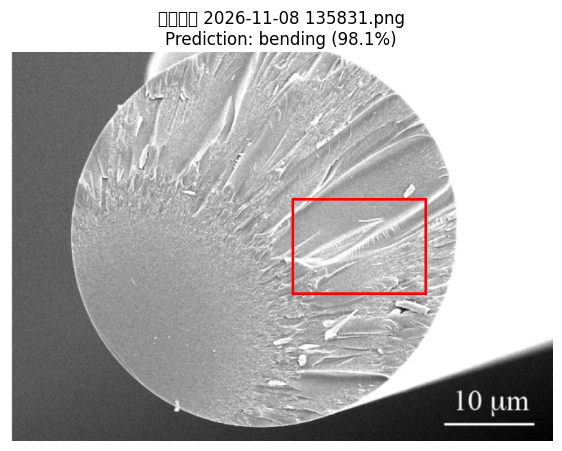

{'원본 파일명': '스크린샷 2026-11-08 135831.png', '예측 유형': 'bending', '박스 표시': 'Grad-CAM 최대 지점 주변 표시', 'bending 점수 (%)': 98.11, 'cleaving 점수 (%)': 1.78, 'fracture 점수 (%)': 0.11, '결과 이미지': '분석결과_001.png'}
결과 폴더: /content/drive/MyDrive/SEM_CNN_3epoch/20261108_041728/new_predictions/20261108_042707_514794
ZIP 파일: /content/drive/MyDrive/SEM_CNN_3epoch/20261108_041728/new_predictions/20261108_042707_514794.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
from pathlib import Path
from io import BytesIO
from datetime import datetime
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageDraw
import torch
import torch.nn.functional as F
from torch import nn
from torchvision import models, transforms
from google.colab import drive, files

drive.mount('/content/drive')
# 비워두면 가장 최근 저장된 모델을 선택합니다.
MODEL_PATH = ''
BOX_SIZE_RATIO = 0.25  # 표시 박스의 가로·세로 비율 (각각 이미지 크기의 25%)
if MODEL_PATH:
    model_path = Path(MODEL_PATH)
else:
    candidates = list(Path('/content/drive/MyDrive/SEM_CNN_3epoch').glob('*/best_model.pt'))
    if not candidates:
        raise FileNotFoundError('best_model.pt가 없습니다. 학습을 완료하거나 MODEL_PATH를 지정하세요.')
    model_path = max(candidates, key=lambda p: p.parent.name)
print('사용 모델:', model_path)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
checkpoint = torch.load(model_path, map_location=device, weights_only=True)
classes = checkpoint['classes']
size = checkpoint.get('image_size', 224)
model = models.resnet18(weights=None)
model.fc = nn.Sequential(nn.Dropout(.3), nn.Linear(model.fc.in_features, len(classes)))
model.load_state_dict(checkpoint['state_dict'])
model.to(device).eval()
preprocess = transforms.Compose([
    transforms.Resize((size, size)), transforms.ToTensor(),
    transforms.Normalize([.485, .456, .406], [.229, .224, .225]),
])

# 마지막 합성곱 층의 활성화와 기울기로 Grad-CAM 계산
activations = {}
def save_activation(module, inputs, output):
    activations['feature'] = output
    output.retain_grad()
hook = model.layer4[-1].register_forward_hook(save_activation)
result_dir = model_path.parent / 'new_predictions' / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
result_dir.mkdir(parents=True, exist_ok=True)
print('분석할 SEM 사진을 한 장 또는 여러 장 선택하세요.')
uploaded = files.upload()
rows, reports = [], []
try:
    for number, (filename, content) in enumerate(uploaded.items(), 1):
        try:
            with Image.open(BytesIO(content)) as source:
                image = ImageOps.exif_transpose(source).convert('RGB')
            x = preprocess(image).unsqueeze(0).to(device).requires_grad_(True)
            model.zero_grad(set_to_none=True)
            logits = model(x)
            probabilities = torch.softmax(logits, dim=1)[0].detach().cpu().numpy()
            index = int(np.argmax(probabilities))
            logits[0, index].backward()
            feature = activations['feature']
            weights = feature.grad.mean(dim=(2, 3), keepdim=True)
            cam = torch.relu((weights * feature).sum(dim=1, keepdim=True))
            cam = F.interpolate(cam, size=(image.height, image.width), mode='bilinear', align_corners=False)[0, 0]
            cam = cam.detach().cpu().numpy()
            peak = float(cam.max())
            annotated = image.copy()
            if np.isfinite(peak) and peak > 1e-12:
                y, x_peak = np.unravel_index(np.argmax(cam), cam.shape)
                bw = max(1, int(image.width * BOX_SIZE_RATIO))
                bh = max(1, int(image.height * BOX_SIZE_RATIO))
                left = max(0, min(image.width-bw, int(x_peak)-bw//2))
                top = max(0, min(image.height-bh, int(y)-bh//2))
                ImageDraw.Draw(annotated).rectangle((left, top, left+bw-1, top+bh-1), outline='red', width=max(2, round(min(image.size)*0.006)))
                box_status = 'Grad-CAM 최대 지점 주변 표시'
            else:
                box_status = '유효한 주목 영역을 찾지 못해 박스 생략'
            output_image = result_dir / f'분석결과_{number:03d}.png'
            annotated.save(output_image)
            row = {'원본 파일명': filename, '예측 유형': classes[index], '박스 표시': box_status,
                   **{f'{name} 점수 (%)': round(float(probabilities[i])*100, 2) for i, name in enumerate(classes)},
                   '결과 이미지': output_image.name}
            rows.append(row)
            reports.append(f"[{number}] {filename}\n예측: {classes[index]}\n" +
                           '\n'.join(f'{name}: {probabilities[i]*100:.2f}%' for i,name in enumerate(classes)) +
                           f'\n{box_status}\n저장: {output_image.name}\n')
            plt.figure(figsize=(7, 6)); plt.imshow(annotated); plt.axis('off')
            plt.title(f'{filename}\nPrediction: {classes[index]} ({probabilities[index]*100:.1f}%)')
            plt.show(); print(row)
        except Exception as e:
            print(f'분석 실패: {filename} — {e}')
finally:
    hook.remove()

if rows:
    pd.DataFrame(rows).to_csv(result_dir/'분석결과.csv', index=False, encoding='utf-8-sig')
    report = 'SEM 이미지 분류 결과\n모델: ' + str(model_path) + '\n\n' + '\n'.join(reports)
    report += '\n빨간 박스는 모델 주목 영역이며 실제 파단 원인을 입증하지 않습니다.\n'
    (result_dir/'분석결과.txt').write_text(report, encoding='utf-8')
    zip_path = result_dir.parent / (result_dir.name + '.zip')
    with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as archive:
        for item in sorted(result_dir.iterdir()):
            if item.is_file(): archive.write(item, arcname=item.name)
    print('결과 폴더:', result_dir)
    print('ZIP 파일:', zip_path)
    files.download(str(zip_path))
else:
    print('분석된 이미지가 없습니다.')
